# Klasifikasi Ekspresi Wajah Manusia pada Citra Grayscale (FER-2013)
### Master Notebook Terstruktur — Siap Jalankan di Google Colab (GPU T4) maupun Lokal

Notebook ini merapikan seluruh alur proyek Data Science dari awal hingga akhir dalam **satu alur linear yang terstruktur**, lengkap dengan penjelasan konseptual dan komentar kode di setiap cell agar mudah dipahami dan dipresentasikan.

## Peta Alur Proyek (9 Tahap Berurutan)
| Tahap | Isi Utama | Aturan Anti-Leakage |
|---|---|---|
| **Tahap 0** | Setup Google Colab, Mount Drive, Aktivasi GPU T4 & Cek Library | — |
| **Tahap 1** | Konfigurasi Global (*Single Source of Truth*) | Path, label 0–6, seed `42` |
| **Tahap 2** | Dataset Inspection (`data/raw/train/` & `data/raw/test/`) | *Read-only*, dataset asli tidak diubah |
| **Tahap 3** | Exploratory Data Analysis (EDA) | Visual & statistik piksel **hanya pada `TRAIN`** |
| **Tahap 4** | Stratified Data Splitting (80% Train / 20% Val) | `TEST` tidak ikut split, 0 overlap |
| **Tahap 5** | Preprocessing, Cache Cepat, Augmentasi & Class Weights | Normalisasi **1×**, augmentasi **hanya saat training** |
| **Tahap 6** | Utilitas Metrik Evaluasi & Metrik Deployment PRD | Accuracy, Macro/Weighted F1, `model_size_mb`, `ms/citra` |
| **Tahap 7** | Pemodelan 4 Arsitektur PRD (**HOG+SVM**, **MLP**, **Custom CNN Baseline & Improved**, **MobileNetV2**) | Training & seleksi **hanya pada `TRAIN` + `VAL`** |
| **Tahap 8** | Komparasi Semua Model pada `Validation Set` | Memilih model pemenang secara objektif di `VAL` |
| **Tahap 9** | Evaluasi Akhir pada `Test Set` (`7.178` citra) | **Hanya dijalankan 1× di akhir** tanpa tuning ulang |

## Cara Menjalankan di Google Colab (3 Langkah Cepat)
1. **Aktifkan GPU di Colab:** Buka menu **Runtime → Change runtime type → Hardware accelerator: T4 GPU → Save**.
2. **Siapkan Folder Proyek di Google Drive:**
   - Upload folder proyek ke Google Drive, misalnya: `MyDrive/FER2013_Project/`
   - Minimal isi folder yang perlu ada:
     - `data/raw/train/` & `data/raw/test/` *(dataset FER-2013)*, **ATAU** file cache `data/processed/fer2013_train_val_uint8_cache.npz` + `data/splits/` *(jauh lebih cepat dimuat di Colab!)*.
     - *(Opsional)* folder `models/` jika kamu ingin langsung memuat model yang sudah terlatih tanpa training ulang.
3. **Jalankan Cell Berurutan dari Atas ke Bawah (`Shift + Enter`):**
   - Sesuaikan `COLAB_DRIVE_PROJECT_DIR` di **Tahap 0** jika nama folder Drive-mu berbeda.
   - Di **Tahap 7**, tersedia saklar `RUN_TRAIN_*` (`True`/`False`) supaya kamu bebas memilih model mana yang ingin dilatih ulang atau langsung dimuat dari file tersimpan.

## Tahap 0 — Setup Environment, Deteksi Colab/Lokal, & Konfigurasi GPU

### Apa yang dilakukan cell di bawah ini?
1. **Mendeteksi otomatis** apakah notebook sedang dijalankan di **Google Colab** atau di **komputer lokal**.
2. Jika di Google Colab: me-*mount* Google Drive ke `/content/drive` dan mengarahkan `PROJECT_ROOT` ke folder proyekmu di Drive.
3. **Mengonfigurasi GPU secara aman (`set_memory_growth=True`)**:
   - Secara default TensorFlow langsung mengambil hampir seluruh memori VRAM GPU di awal.
   - Dengan `set_memory_growth=True`, GPU hanya memakai VRAM seperlunya sehingga aman untuk GPU kelas 6GB–15GB (seperti RTX 3050 6GB atau Colab T4 15GB) dan tetap berjalan normal jika hanya tersedia CPU.
4. **Memeriksa paket wajib** (`tensorflow`, `scikit-learn`, `scikit-image`, `joblib`, `pandas`, `matplotlib`, `pillow`) dan mencetak informasi versi serta status GPU.

In [1]:
import importlib.util
import os
import sys
from pathlib import Path

# 1. Deteksi apakah notebook berjalan di Google Colab
IN_COLAB = "google.colab" in sys.modules

# Ubah path ini jika nama folder proyek di Google Drive-mu berbeda
COLAB_DRIVE_PROJECT_DIR = "/content/drive/MyDrive/FER2013_Project"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path(COLAB_DRIVE_PROJECT_DIR)
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    os.chdir(PROJECT_ROOT)
    print(f"[COLAB MODE] Google Drive terpasang. PROJECT_ROOT = {PROJECT_ROOT}")
else:
    CWD = Path.cwd().resolve()
    PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
    print(f"[LOCAL MODE] PROJECT_ROOT = {PROJECT_ROOT}")

# 2. Cek ketersediaan paket penting (di Colab biasanya semuanya sudah terpasang)
required_pkgs = {
    "tensorflow": "tensorflow",
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "pillow",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "skimage": "scikit-image",
    "joblib": "joblib",
}
missing_pkgs = [pip_name for mod, pip_name in required_pkgs.items() if importlib.util.find_spec(mod) is None]
if missing_pkgs:
    print(f"Paket belum terpasang: {missing_pkgs}")
    print("Jalankan perintah berikut di cell baru jika diperlukan:")
    print(f"  %pip install -q {' '.join(missing_pkgs)}")
else:
    print("Semua library inti sudah tersedia!")

# 3. Import library utama & konfigurasi GPU memory growth
import hashlib
import json
import math
import random
import time
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image, ImageFile
from skimage.feature import hog
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from tensorflow import keras
from tensorflow.keras import layers

# Mode ketat agar gambar terpotong/rusak tidak diam-diam terbaca
ImageFile.LOAD_TRUNCATED_IMAGES = False

# Konfigurasi GPU memory growth (aman untuk T4 / RTX 3050 6GB maupun CPU)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    DEVICE_STR = f"GPU ({len(gpus)} device: {gpus[0].name})"
else:
    DEVICE_STR = "CPU (TensorFlow oneDNN)"

print(f"Python     : {sys.version.split()[0]}")
print(f"TensorFlow : {tf.__version__} | Keras: {keras.__version__}")
print(f"Device     : {DEVICE_STR}")

[LOCAL MODE] PROJECT_ROOT = D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!
Semua library inti sudah tersedia!
Python     : 3.13.14
TensorFlow : 2.21.0 | Keras: 3.15.1
Device     : CPU (TensorFlow oneDNN)


## Tahap 1 — Konfigurasi Global Proyek (*Single Source of Truth*)

### Mengapa tahap ini penting?
Dalam proyek Data Science, menyebar angka seperti ukuran gambar (`48`), jumlah kelas (`7`), mapping label (`angry=0` s.d. `surprise=6`), atau `RANDOM_SEED` di banyak tempat sangat rawan menimbulkan bug (misalnya urutan label tertukar antara training dan evaluasi).

### Penjelasan parameter di cell berikut:
- **Path Folder:** `data/raw/` (dataset asli, *read-only*), `data/splits/` (manifest CSV split), `data/processed/` (cache array cepat), `models/` (model tersimpan), dan `outputs/` (grafik & laporan).
- **Dimensi Input:** `INPUT_SHAPE = (48, 48, 1)` → tinggi 48 piksel, lebar 48 piksel, 1 kanal grayscale.
- **Label Mapping Kanonis:** Urutan alfabetis `0..6` yang wajib identik di seluruh 4 model (HOG+SVM, MLP, Custom CNN, MobileNetV2).
- **`RANDOM_SEED = 42`:** Mengunci keacakan NumPy, Python, dan TensorFlow agar hasil split & eksperimen dapat direproduksi.
- **`AugmentationConfig`:** Parameter augmentasi ringan (*Horizontal Flip*, *Rotation ±10°*, *Zoom ±10%*, *Translation ±5%*) yang **hanya boleh aktif saat training**.

In [2]:
# --- Lokasi Direktori Proyek ---
DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
RAW_TRAIN_DIR = RAW_DATA_DIR / "train"
RAW_TEST_DIR = RAW_DATA_DIR / "test"
SPLITS_DIR = DATA_DIR / "splits"
PROCESSED_DIR = DATA_DIR / "processed"
TRAIN_VAL_CACHE_PATH = PROCESSED_DIR / "fer2013_train_val_uint8_cache.npz"

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
REPORTS_DIR = OUTPUTS_DIR / "reports"

# Buat folder output otomatis jika belum ada (tidak pernah memodifikasi data/raw/)
for _d in (SPLITS_DIR, PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, REPORTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# --- Spesifikasi Citra & Label Kanonis ---
IMAGE_HEIGHT = 48
IMAGE_WIDTH = 48
IMAGE_SIZE = (IMAGE_WIDTH, IMAGE_HEIGHT)       # (W, H) untuk Pillow
INPUT_SHAPE = (IMAGE_HEIGHT, IMAGE_WIDTH, 1)   # (48, 48, 1) untuk Keras/CNN

LABEL_TO_ID = {
    "angry": 0,
    "disgust": 1,
    "fear": 2,
    "happy": 3,
    "neutral": 4,
    "sad": 5,
    "surprise": 6,
}
ID_TO_LABEL = {idx: name for name, idx in LABEL_TO_ID.items()}
CLASS_DISPLAY_NAMES = [ID_TO_LABEL[i].capitalize() for i in range(len(LABEL_TO_ID))]
NUM_CLASSES = len(LABEL_TO_ID)
VALID_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# --- Hyperparameter Reproduksibilitas & Training ---
RANDOM_SEED = 42
TRAIN_RATIO = 0.80
VAL_RATIO = 0.20
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 4
REDUCE_LR_MIN_LR = 1e-6


@dataclass(frozen=True)
class AugmentationConfig:
    '''Parameter augmentasi geometri ringan khusus data TRAINING.'''
    horizontal_flip_prob: float = 0.50
    rotation_range_deg: float = 10.0   # +-10 derajat
    zoom_range: float = 0.10           # +-10% zoom
    translation_range: float = 0.05    # +-5% pergeseran (~2.4 px pada 48x48)


AUG_CONFIG = AugmentationConfig()

# Kunci random seed global & gaya visualisasi Matplotlib
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
keras.utils.set_random_seed(RANDOM_SEED)

CLASS_COLORS = {
    "happy": "#2A9D8F",
    "neutral": "#457B9D",
    "sad": "#5C6BC0",
    "fear": "#E76F51",
    "angry": "#D62828",
    "surprise": "#F4A261",
    "disgust": "#8E44AD",
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#FAFAFA",
    "axes.edgecolor": "#CCCCCC",
    "axes.grid": True,
    "grid.color": "#E5E5E5",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

print("Konfigurasi siap!")
print(f"  INPUT_SHAPE : {INPUT_SHAPE}")
print(f"  LABEL_TO_ID : {LABEL_TO_ID}")
print(f"  RAW_TRAIN   : {'ADA' if RAW_TRAIN_DIR.exists() else 'BELUM ADA'} ({RAW_TRAIN_DIR})")
print(f"  RAW_TEST    : {'ADA' if RAW_TEST_DIR.exists() else 'BELUM ADA'} ({RAW_TEST_DIR})")
print(f"  CACHE .NPZ  : {'ADA' if TRAIN_VAL_CACHE_PATH.exists() else 'BELUM ADA'} ({TRAIN_VAL_CACHE_PATH})")

Konfigurasi siap!
  INPUT_SHAPE : (48, 48, 1)
  LABEL_TO_ID : {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
  RAW_TRAIN   : ADA (D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\data\raw\train)
  RAW_TEST    : ADA (D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\data\raw\test)
  CACHE .NPZ  : ADA (D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\data\processed\fer2013_train_val_uint8_cache.npz)


## Tahap 2 — Dataset Inspection (*Read-Only*)

### Tujuan tahap ini
Sebelum membuat grafik atau melatih model, kita **wajib memeriksa kondisi mentah dataset** terlebih dahulu:
1. Apakah folder `train/` dan `test/` memiliki **7 kategori ekspresi yang persis sama**?
2. Berapa jumlah file di setiap kategori?
3. Apakah ada gambar rusak (*corrupt* / *truncated*), dimensi aneh (bukan `48×48`), atau mode warna selain grayscale (`L`)?
4. Apakah ada gambar hitam polos (*all-zero*, seluruh piksel bernilai `0`)?

### Penjelasan kode di bawah
- Jika `data/raw/` tersedia, cell ini memeriksa struktur folder `train/` & `test/` secara *read-only* dan melakukan verifikasi sampel/penuh gambar (set `FULL_IMAGE_SCAN = True` jika ingin memindai 100% file; default `False` memindai cepat metadata folder + 500 sampel agar cepat di Google Drive).
- **Catatan temuan aktual pada FER-2013 kita:** Total `35.887` gambar (`28.709` train + `7.178` test), **0 gambar rusak**, **100% seragam `48×48` grayscale (`L`) JPEG**, namun ditemukan **12 citra hitam polos (`all-zero`)** (`11` di train, `1` di test) dan rasio ketimpangan **`happy : disgust = 16,55 : 1`**.

In [3]:
FULL_IMAGE_SCAN = False  # Ubah ke True jika ingin scan 100% file dari disk (di Drive bisa 1-3 menit)

if RAW_TRAIN_DIR.exists() and RAW_TEST_DIR.exists():
    train_cats = sorted(p.name for p in RAW_TRAIN_DIR.iterdir() if p.is_dir())
    test_cats = sorted(p.name for p in RAW_TEST_DIR.iterdir() if p.is_dir())
    assert train_cats == test_cats == list(LABEL_TO_ID.keys()), (
        f"Ketidakkonsistenan kategori! train={train_cats}, test={test_cats}"
    )

    inspect_rows = []
    train_file_paths = []
    for cls in train_cats:
        tr_files = sorted(p for p in (RAW_TRAIN_DIR / cls).iterdir() if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS)
        te_files = sorted(p for p in (RAW_TEST_DIR / cls).iterdir() if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS)
        train_file_paths.extend(tr_files)
        inspect_rows.append({
            "label_id": LABEL_TO_ID[cls],
            "class_name": cls,
            "raw_train_count": len(tr_files),
            "raw_test_count": len(te_files),
            "total": len(tr_files) + len(te_files),
        })

    inspect_df = pd.DataFrame(inspect_rows)
    inspect_df["train_pct"] = (inspect_df["raw_train_count"] / inspect_df["raw_train_count"].sum() * 100).round(2)
    inspect_df["test_pct"] = (inspect_df["raw_test_count"] / inspect_df["raw_test_count"].sum() * 100).round(2)

    # Pemeriksaan dimensi, mode warna, format aktual, dan kerusakan file
    check_list = train_file_paths if FULL_IMAGE_SCAN else random.Random(RANDOM_SEED).sample(train_file_paths, min(500, len(train_file_paths)))
    dims_counter, modes_counter, fmts_counter = Counter(), Counter(), Counter()
    corrupted_count, all_zero_count = 0, 0

    for fp in check_list:
        try:
            with Image.open(fp) as im:
                im.load()
                dims_counter[f"{im.size[0]}x{im.size[1]}"] += 1
                modes_counter[im.mode] += 1
                fmts_counter[im.format] += 1
                mn, mx = im.getextrema()
                if mn == mx:
                    all_zero_count += 1
        except Exception:
            corrupted_count += 1

    print("=== HASIL DATASET INSPECTION (READ-ONLY) ===")
    print(f"Konsistensi 7 kategori train vs test : EXACT MATCH ({train_cats})")
    print(f"Total gambar raw/train               : {inspect_df['raw_train_count'].sum():,}")
    print(f"Total gambar raw/test                : {inspect_df['raw_test_count'].sum():,}")
    print(f"Total keseluruhan                    : {inspect_df['total'].sum():,}")
    print(f"Sampel diperiksa ({len(check_list):,} file)     : dims={dict(dims_counter)}, modes={dict(modes_counter)}, formats={dict(fmts_counter)}")
    print(f"File rusak / konstan (all-zero)      : {corrupted_count} rusak | {all_zero_count} piksel konstan")
    display(inspect_df)
else:
    print("Folder data/raw/ belum ditemukan di PROJECT_ROOT.")
    print("Pastikan data/raw/train & data/raw/test sudah di-upload ke Google Drive,")
    print("atau lanjutkan ke Tahap 5 jika kamu langsung menggunakan cache .npz.")

=== HASIL DATASET INSPECTION (READ-ONLY) ===
Konsistensi 7 kategori train vs test : EXACT MATCH (['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise'])
Total gambar raw/train               : 28,709
Total gambar raw/test                : 7,178
Total keseluruhan                    : 35,887
Sampel diperiksa (500 file)     : dims={'48x48': 500}, modes={'L': 500}, formats={'JPEG': 500}
File rusak / konstan (all-zero)      : 0 rusak | 1 piksel konstan


,label_id,class_name,raw_train_count,raw_test_count,total,train_pct,test_pct
0,0,angry,3995,958,4953,13.92,13.35
1,1,disgust,436,111,547,1.52,1.55
2,2,fear,4097,1024,5121,14.27,14.27
3,3,happy,7215,1774,8989,25.13,24.71
4,4,neutral,4965,1233,6198,17.29,17.18
5,5,sad,4830,1247,6077,16.82,17.37
6,6,surprise,3171,831,4002,11.05,11.58


## Tahap 3 — Exploratory Data Analysis (EDA) pada `TRAIN`

### Prinsip penting EDA
- Seluruh analisis distribusi kelas, contoh citra, dan statistik piksel dilakukan **HANYA pada `data/raw/train/`** agar keputusan preprocessing/model tidak "mengintip" `data/raw/test/` (*anti-data leakage*).
- **Apa yang kita lihat di cell visualisasi berikut?**
  1. **Bar Chart Distribusi Kelas `TRAIN`:** Membandingkan jumlah gambar tiap ekspresi terhadap garis seimbang ideal (`28.709 / 7 ≈ 4.101` gambar/kelas). Terlihat jelas `happy` mendominasi (`25,13%`) sedangkan `disgust` sangat minoritas (`1,52%`, rasio ketimpangan **`16,55 : 1`**).
  2. **Grid Contoh Citra Grayscale (7 Kelas × 5 Sampel):** Melihat langsung wujud citra wajah `48×48` grayscale, variasi pencahayaan, pose, hingga *noise* bawaan FER-2013 (oklusi tangan, *watermark*, dan resolusi rendah).

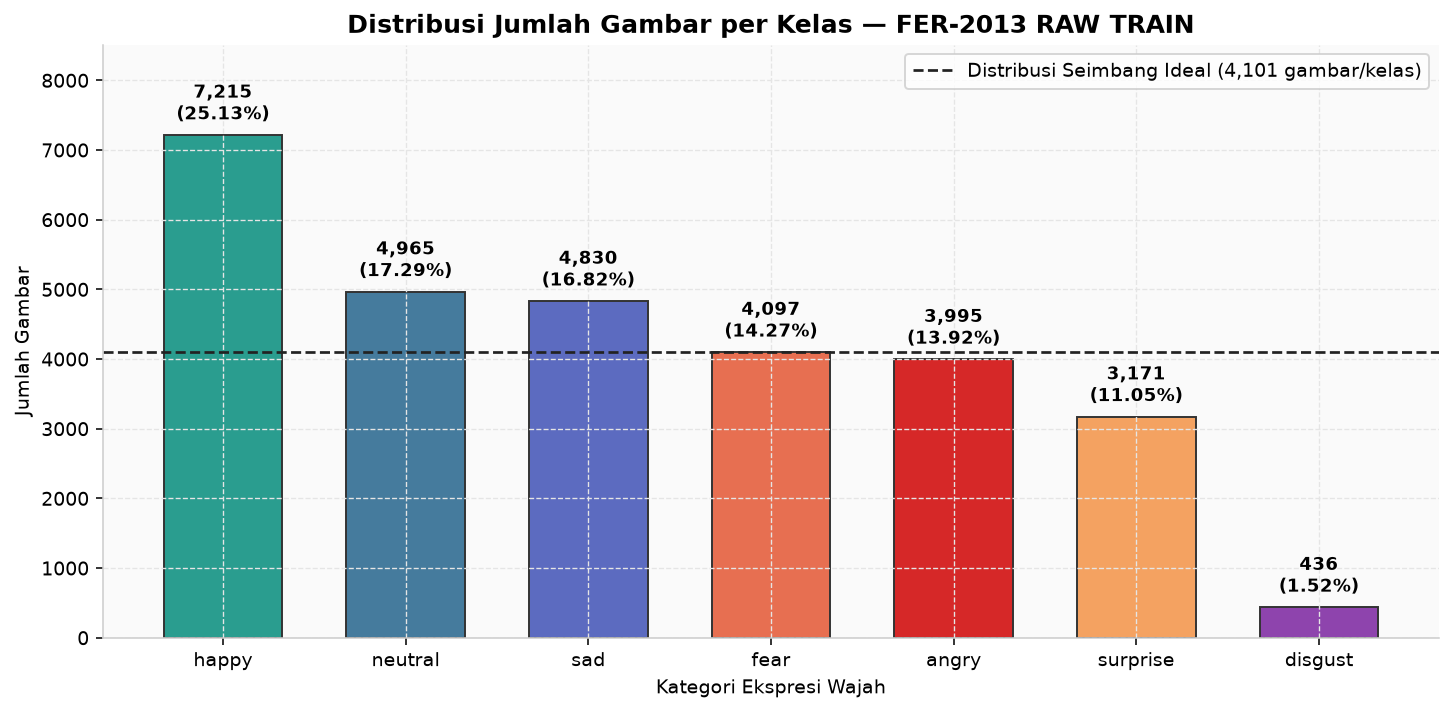

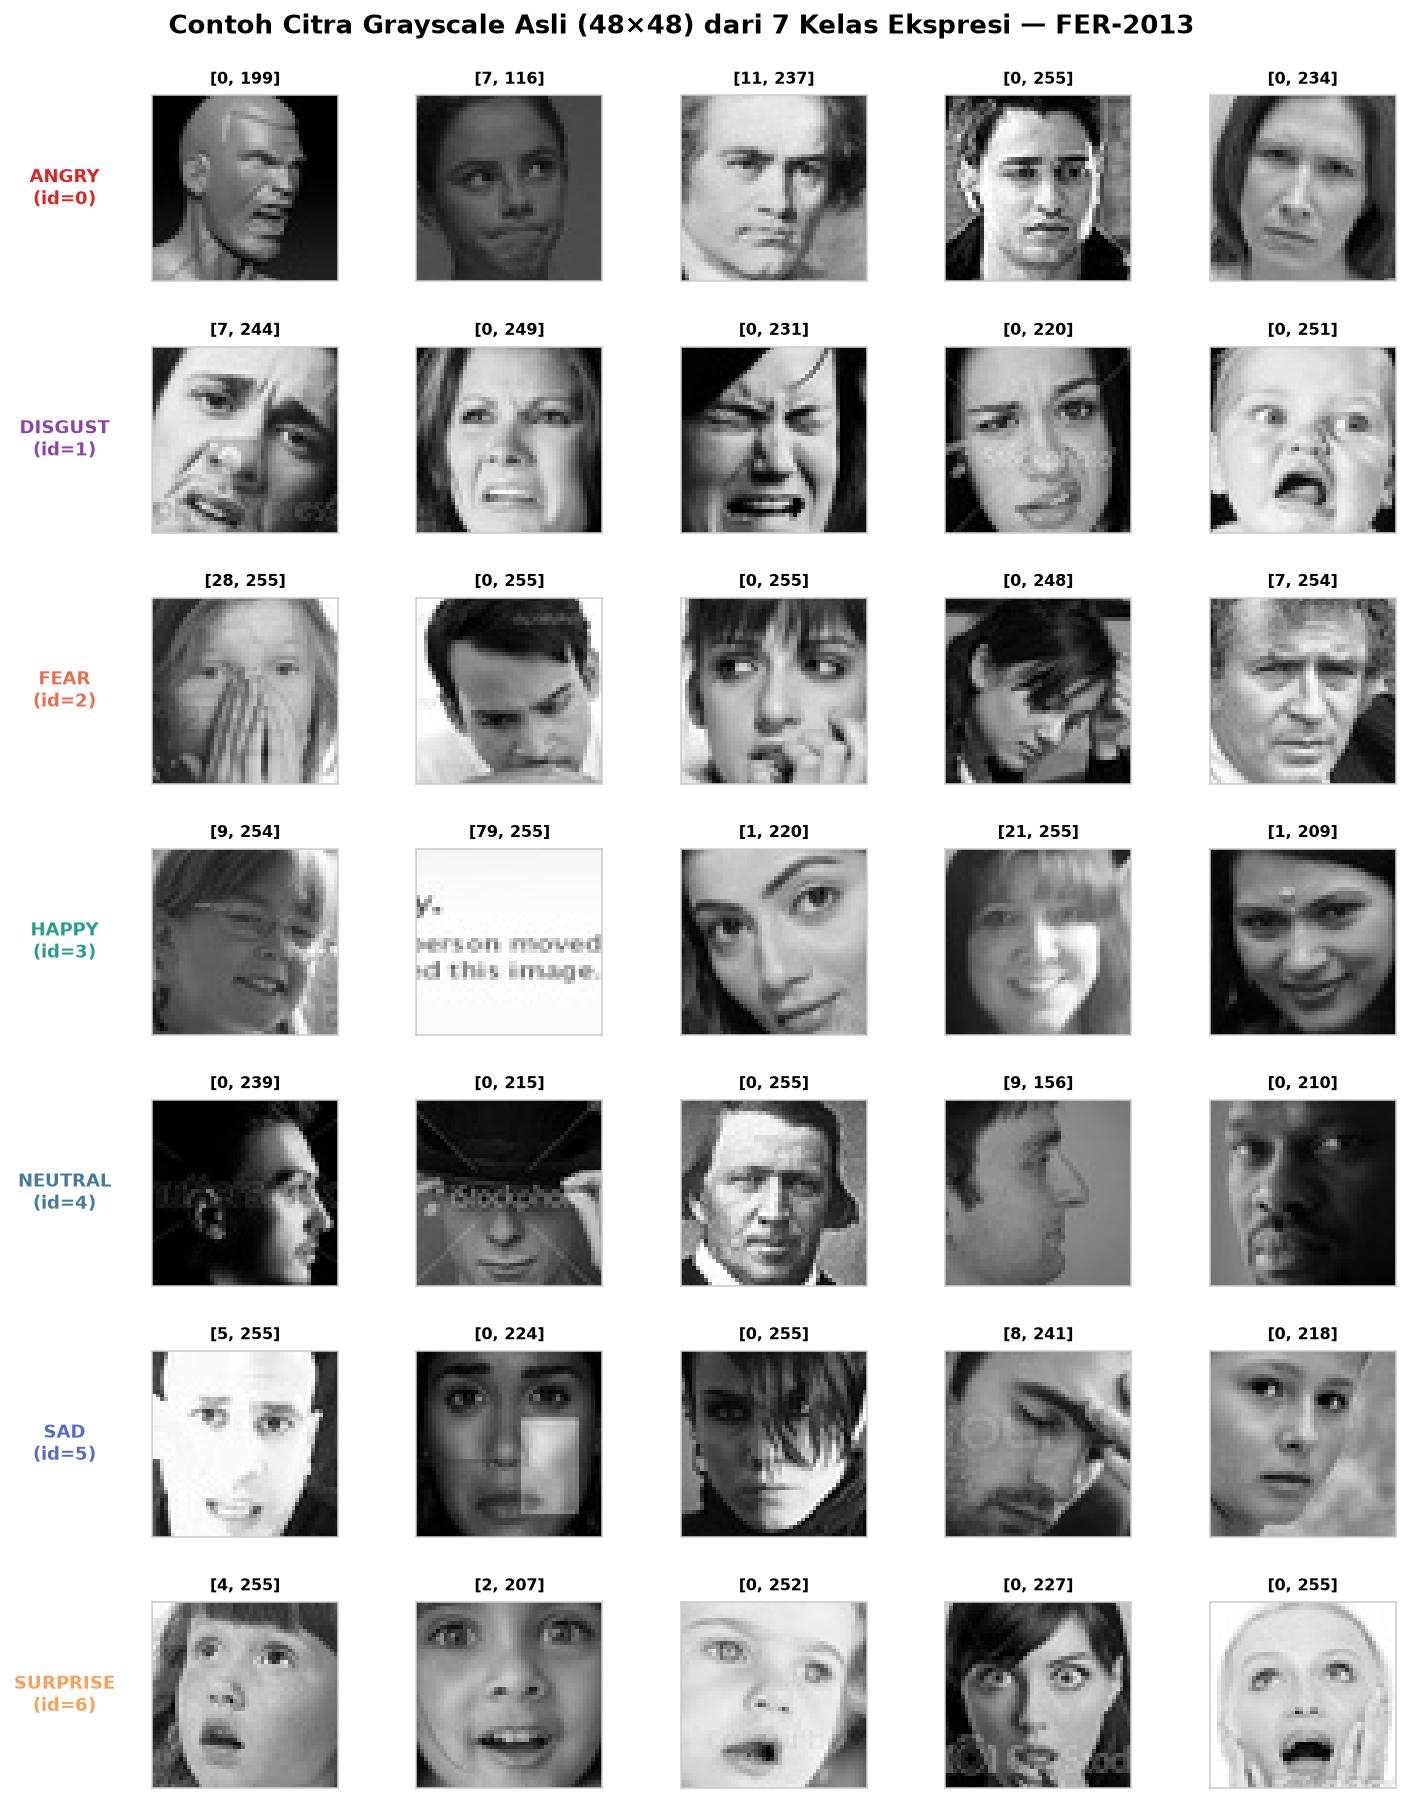

In [4]:
if RAW_TRAIN_DIR.exists():
    # --- 1. Bar Chart Distribusi Kelas pada data/raw/train/ ---
    sorted_df = inspect_df.sort_values("raw_train_count", ascending=False).reset_index(drop=True)
    classes_sorted = sorted_df["class_name"].tolist()
    counts_sorted = sorted_df["raw_train_count"].tolist()
    pcts_sorted = sorted_df["train_pct"].tolist()
    ideal_count = sum(counts_sorted) / len(classes_sorted)

    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    bars = ax.bar(
        classes_sorted,
        counts_sorted,
        color=[CLASS_COLORS[c] for c in classes_sorted],
        edgecolor="#333333",
        width=0.65,
    )
    ax.axhline(ideal_count, color="#222222", linestyle="--", linewidth=1.4,
               label=f"Distribusi Seimbang Ideal ({ideal_count:,.0f} gambar/kelas)")
    for bar, cnt, pct in zip(bars, counts_sorted, pcts_sorted):
        ax.text(bar.get_x() + bar.get_width() / 2, cnt + 140, f"{cnt:,}\n({pct:.2f}%)",
                ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_title("Distribusi Jumlah Gambar per Kelas — FER-2013 RAW TRAIN")
    ax.set_xlabel("Kategori Ekspresi Wajah")
    ax.set_ylabel("Jumlah Gambar")
    ax.set_ylim(0, max(counts_sorted) * 1.18)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper right", frameon=True, facecolor="white")
    plt.tight_layout()
    plt.show()

    # --- 2. Contoh Citra Grayscale 48x48 dari 7 Kelas ---
    rng_vis = random.Random(RANDOM_SEED)
    fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(11, 13), gridspec_kw={"wspace": 0.12, "hspace": 0.35})
    for r, cls in enumerate(sorted(LABEL_TO_ID.keys())):
        files = sorted(p for p in (RAW_TRAIN_DIR / cls).iterdir() if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS)
        picks = rng_vis.sample(files, 5)
        for c, fp in enumerate(picks):
            ax = axes[r, c]
            with Image.open(fp) as im:
                arr = np.asarray(im.convert("L"), dtype=np.uint8)
            ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"[{arr.min()}, {arr.max()}]", fontsize=8)
            if c == 0:
                ax.set_ylabel(f"{cls.upper()}\n(id={LABEL_TO_ID[cls]})", fontsize=9.5,
                              fontweight="bold", color=CLASS_COLORS[cls], rotation=0, labelpad=45, va="center")
    fig.suptitle("Contoh Citra Grayscale Asli (48×48) dari 7 Kelas Ekspresi — FER-2013", fontsize=13.5, fontweight="bold", y=0.995)
    plt.subplots_adjust(left=0.14, right=0.98, top=0.95, bottom=0.02)
    plt.show()
else:
    print("Melewati visualisasi EDA mentah karena data/raw/train tidak ditemukan.")

## Tahap 4 — Stratified Data Splitting (80% Training / 20% Validation, `TEST` Terpisah)

### Mengapa `data/raw/train/` dibagi 80:20 padahal sudah ada `data/raw/test/`?
```text
Total FER-2013 (35.887 gambar — 100%)
├── data/raw/train/ (28.709 gambar) ──[Stratified Split 80:20, seed=42]──►
│   ├── Training   (data/splits/train.csv) : 22.967 gambar (64% total) → untuk model.fit()
│   └── Validation (data/splits/val.csv)   :  5.742 gambar (16% total) → untuk EarlyStopping, ReduceLR, ModelCheckpoint, & pilih model terbaik
└── data/raw/test/  (7.178 gambar)  ──[DIKUNCI / TIDAK IKUT SPLIT]──►
    └── Testing    (data/splits/test.csv)  :  7.178 gambar (20% total) → evaluasi akhir 1× saja!
```
- **Stratified Split** memastikan proporsi setiap kelas (termasuk `disgust` yang hanya `1,52%`) tetap sama persis antara Training (`80%`) dan Validation (`20%`).
- **Perilaku cell di bawah:** Jika `data/splits/train.csv`, `val.csv`, `test.csv`, dan `label_mapping.json` sudah ada, cell ini **langsung memakainya kembali** (tidak membuat split kedua yang bertentangan). Jika belum ada, cell ini membuatnya otomatis secara deterministik (`seed=42`) dan memverifikasi **0 overlap**.

In [5]:
def _collect_manifest(split_dir: Path, split_name: str) -> pd.DataFrame:
    rows = []
    for cls_name, label_id in sorted(LABEL_TO_ID.items(), key=lambda kv: kv[1]):
        cls_dir = split_dir / cls_name
        files = sorted(
            (p for p in cls_dir.iterdir() if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS),
            key=lambda p: p.name,
        )
        for fp in files:
            rows.append({
                "filepath": fp.resolve().relative_to(PROJECT_ROOT.resolve()).as_posix(),
                "filename": fp.name,
                "class_name": cls_name,
                "label_id": label_id,
                "split": split_name,
            })
    return pd.DataFrame(rows)


def _stratified_split_80_20(raw_train_df: pd.DataFrame, val_ratio: float = VAL_RATIO, seed: int = RANDOM_SEED):
    ordered = raw_train_df.sort_values(["label_id", "filepath"]).reset_index(drop=True)
    class_counts = {c: int((ordered["class_name"] == c).sum()) for c in LABEL_TO_ID.keys()}
    total = sum(class_counts.values())
    target_val = int(round(total * val_ratio))

    # Alokasi Largest Remainder agar total val tepat round(N * 0.20)
    quotas = {c: cnt * val_ratio for c, cnt in class_counts.items()}
    val_alloc = {c: int(math.floor(q)) for c, q in quotas.items()}
    rem = {c: quotas[c] - val_alloc[c] for c in class_counts}
    need = target_val - sum(val_alloc.values())
    for c in sorted(class_counts.keys(), key=lambda k: (-rem[k], k)):
        if need <= 0:
            break
        val_alloc[c] += 1
        need -= 1

    rng = np.random.default_rng(seed)
    tr_parts, va_parts = [], []
    for cls_name in LABEL_TO_ID.keys():
        sub = ordered[ordered["class_name"] == cls_name].reset_index(drop=True)
        perm = rng.permutation(len(sub))
        n_val = val_alloc[cls_name]
        va_parts.append(sub.iloc[np.sort(perm[:n_val])])
        tr_parts.append(sub.iloc[np.sort(perm[n_val:])])

    train_df = pd.concat(tr_parts, ignore_index=True).assign(split="train").sort_values(["label_id", "filepath"]).reset_index(drop=True)
    val_df = pd.concat(va_parts, ignore_index=True).assign(split="val").sort_values(["label_id", "filepath"]).reset_index(drop=True)
    return train_df, val_df


# Gunakan ulang manifest split yang sudah ada agar 100% konsisten dengan eksperimen lokal
split_files_exist = all((SPLITS_DIR / f).exists() for f in ("train.csv", "val.csv", "test.csv", "label_mapping.json"))

if split_files_exist:
    train_df = pd.read_csv(SPLITS_DIR / "train.csv")
    val_df = pd.read_csv(SPLITS_DIR / "val.csv")
    test_df = pd.read_csv(SPLITS_DIR / "test.csv")
    print("[REUSED] Menggunakan kembali split manifest yang sudah tersimpan di data/splits/.")
elif RAW_TRAIN_DIR.exists() and RAW_TEST_DIR.exists():
    raw_train_df = _collect_manifest(RAW_TRAIN_DIR, "raw_train")
    test_df = _collect_manifest(RAW_TEST_DIR, "test")
    train_df, val_df = _stratified_split_80_20(raw_train_df, val_ratio=VAL_RATIO, seed=RANDOM_SEED)

    train_df.to_csv(SPLITS_DIR / "train.csv", index=False)
    val_df.to_csv(SPLITS_DIR / "val.csv", index=False)
    test_df.to_csv(SPLITS_DIR / "test.csv", index=False)
    (SPLITS_DIR / "label_mapping.json").write_text(
        json.dumps({"num_classes": NUM_CLASSES, "classes": list(LABEL_TO_ID.keys()),
                    "label_to_id": LABEL_TO_ID, "id_to_label": {str(k): v for k, v in ID_TO_LABEL.items()}}, indent=2),
        encoding="utf-8",
    )
    print("[CREATED] Stratified 80/20 split berhasil dibuat dan disimpan ke data/splits/.")
else:
    raise FileNotFoundError("Baik data/splits/*.csv maupun data/raw/ tidak ditemukan!")

# Verifikasi ketat anti-leakage
assert set(train_df["filepath"]).isdisjoint(set(val_df["filepath"])), "Overlap antara train dan val!"
assert set(test_df["filepath"]).isdisjoint(set(train_df["filepath"]) | set(val_df["filepath"])), "Kebocoran test!"

split_summary = pd.DataFrame([
    {
        "label_id": lid,
        "class_name": cname,
        "train (80%)": int((train_df["label_id"] == lid).sum()),
        "val (20%)": int((val_df["label_id"] == lid).sum()),
        "test (terpisah)": int((test_df["label_id"] == lid).sum()),
    }
    for cname, lid in LABEL_TO_ID.items()
])
print(f"Train = {len(train_df):,} | Val = {len(val_df):,} | Test (terisolasi) = {len(test_df):,}")
display(split_summary)

[REUSED] Menggunakan kembali split manifest yang sudah tersimpan di data/splits/.
Train = 22,967 | Val = 5,742 | Test (terisolasi) = 7,178


,label_id,class_name,train (80%),val (20%),test (terpisah)
0,0,angry,3196,799,958
1,1,disgust,349,87,111
2,2,fear,3277,820,1024
3,3,happy,5772,1443,1774
4,4,neutral,3972,993,1233
5,5,sad,3864,966,1247
6,6,surprise,2537,634,831


## Tahap 5 — Preprocessing Citra, Caching Cepat, Augmentasi & `class_weight`

### Alur Preprocessing (Single-Pass, Anti Normalisasi Ganda)
Setiap citra melewati langkah presisi berikut:
1. **Grayscale 1 kanal (`L`):** memastikan format `(48, 48, 1)` meskipun ada citra RGB.
2. **Resize ke `48×48`** (hanya jika dimensinya berbeda, memakai interpolasi bilinear).
3. **Normalisasi tunggal `[0, 255] → float32 [0.0, 1.0]`** melalui `normalize_pixels()`. Fungsi ini dilengkapi **guardrail**: jika tidak sengaja diberi array `float` yang sudah di `[0, 1]`, fungsi langsung menolak dengan `ValueError` agar tidak pernah terjadi normalisasi dua kali (`/ 255 / 255`).
4. **Cache Lossless `.npz` (`63,3 MB`):** Membaca 28.709 file kecil satu per satu dari Google Drive bisa memakan waktu lama. Jika `data/processed/fer2013_train_val_uint8_cache.npz` sudah ada dan cocok *signature*-nya, pemuatan seluruh `X_train` & `X_val` hanya butuh **`< 1 detik`**!
5. **Data Augmentation On-The-Fly (`build_data_augmentation()`):** Layer Keras `RandomFlip`, `RandomRotation (±10°)`, `RandomZoom (±10%)`, dan `RandomTranslation (±5%)` **otomatis hanya aktif saat `training=True`** dan nonaktif saat validasi/testing.
6. **Penanganan Class Imbalance (`class_weight`):** Dihitung **hanya dari `y_train`**:
   - `balanced`: $w_c = N / (7 \cdot n_c)$ (memberi `disgust = 9,40×`) — dipakai pada Baseline CNN.
   - `smoothed`: $\sqrt{N / (7 \cdot n_c)}$ dinormalisasi mean `1,0` (memberi `disgust = 2,44×`) — jauh lebih stabil dan dipakai pada Improved CNN, MLP, & MobileNetV2!

In [6]:
def normalize_pixels(arr: np.ndarray) -> np.ndarray:
    '''Normalisasi piksel [0, 255] -> float32 [0.0, 1.0] tepat SATU kali dengan proteksi ganda.'''
    arr = np.asarray(arr)
    if np.issubdtype(arr.dtype, np.floating):
        if float(arr.min()) >= 0.0 and float(arr.max()) <= 1.0:
            raise ValueError("Array sudah ternormalisasi [0, 1]! Menolak normalisasi ganda.")
        return np.clip(arr.astype(np.float32) / 255.0, 0.0, 1.0)
    return np.clip(arr.astype(np.float32) / 255.0, 0.0, 1.0)


def load_images_from_manifest(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    '''Membaca daftar citra dari manifest CSV menjadi (X_uint8 [N,48,48,1], y [N]).'''
    n = len(df)
    x_u8 = np.empty((n, IMAGE_HEIGHT, IMAGE_WIDTH, 1), dtype=np.uint8)
    y = df["label_id"].astype(np.int64).to_numpy()
    for i, rel_path in enumerate(df["filepath"]):
        with Image.open(PROJECT_ROOT / rel_path) as im:
            im.load()
            if im.mode != "L":
                im = im.convert("L")
            if im.size != IMAGE_SIZE:
                im = im.resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)
            x_u8[i, :, :, 0] = np.asarray(im, dtype=np.uint8)
    return x_u8, y


def _splits_signature() -> str:
    h = hashlib.sha256()
    for name in ("train.csv", "val.csv", "label_mapping.json"):
        h.update((SPLITS_DIR / name).read_bytes())
    return h.hexdigest()


# --- Muat TRAIN & VAL (TIDAK menyentuh TEST) ---
t0 = time.perf_counter()
sig = _splits_signature()
if TRAIN_VAL_CACHE_PATH.exists():
    with np.load(TRAIN_VAL_CACHE_PATH, allow_pickle=False) as z:
        cache_ok = str(z["splits_signature"]) == sig
        if cache_ok:
            x_train_u8, y_train = z["x_train_uint8"], z["y_train"].astype(np.int64)
            x_val_u8, y_val = z["x_val_uint8"], z["y_val"].astype(np.int64)
            from_cache = True
        else:
            from_cache = False
else:
    from_cache = False

if not from_cache:
    print("Memuat citra dari disk & membuat cache lossless uint8 (sekali saja)...")
    x_train_u8, y_train = load_images_from_manifest(train_df)
    x_val_u8, y_val = load_images_from_manifest(val_df)
    np.savez(
        TRAIN_VAL_CACHE_PATH,
        splits_signature=np.array(sig),
        x_train_uint8=x_train_u8,
        y_train=y_train,
        x_val_uint8=x_val_u8,
        y_val=y_val,
    )

# Normalisasi tunggal ke float32 [0.0, 1.0]
x_train = normalize_pixels(x_train_u8)
x_val = normalize_pixels(x_val_u8)

# Bungkus ke tf.data.Dataset untuk training cepat di GPU/CPU
train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(buffer_size=len(x_train), seed=RANDOM_SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


def compute_class_weights(y_tr: np.ndarray, mode: str = "smoothed") -> dict[int, float] | None:
    '''Menghitung class_weight khusus dari y_train (balanced | smoothed | none).'''
    if mode == "none":
        return None
    total = len(y_tr)
    balanced = {c: total / (NUM_CLASSES * int((y_tr == c).sum())) for c in range(NUM_CLASSES)}
    if mode == "balanced":
        return {k: round(v, 6) for k, v in balanced.items()}
    if mode == "smoothed":
        sq = {k: float(np.sqrt(v)) for k, v in balanced.items()}
        mean_sq = float(np.mean(list(sq.values())))
        return {k: round(v / mean_sq, 6) for k, v in sq.items()}
    raise ValueError(f"Mode tidak dikenal: {mode}")


def build_data_augmentation(include_translation: bool = True, seed: int = RANDOM_SEED) -> keras.Sequential:
    '''Blok augmentasi ringan Keras: HANYA aktif saat training=True.'''
    aug_layers = [
        layers.RandomFlip("horizontal", seed=seed, name="aug_horizontal_flip"),
        layers.RandomRotation(AUG_CONFIG.rotation_range_deg / 360.0, fill_mode="nearest", interpolation="bilinear", seed=seed + 1, name="aug_light_rotation"),
        layers.RandomZoom((-AUG_CONFIG.zoom_range, AUG_CONFIG.zoom_range), (-AUG_CONFIG.zoom_range, AUG_CONFIG.zoom_range), fill_mode="nearest", interpolation="bilinear", seed=seed + 2, name="aug_light_zoom"),
    ]
    if include_translation:
        aug_layers.append(
            layers.RandomTranslation((-AUG_CONFIG.translation_range, AUG_CONFIG.translation_range), (-AUG_CONFIG.translation_range, AUG_CONFIG.translation_range), fill_mode="nearest", interpolation="bilinear", seed=seed + 3, name="aug_light_translation")
        )
    return keras.Sequential(aug_layers, name="data_augmentation")


CLASS_WEIGHTS_BALANCED = compute_class_weights(y_train, mode="balanced")
CLASS_WEIGHTS_SMOOTHED = compute_class_weights(y_train, mode="smoothed")

print(f"Dimuat dalam {time.perf_counter() - t0:.2f}s (from_cache={from_cache})")
print(f"x_train: {x_train.shape} {x_train.dtype} [{x_train.min():.2f}, {x_train.max():.2f}]")
print(f"x_val  : {x_val.shape} {x_val.dtype} [{x_val.min():.2f}, {x_val.max():.2f}]")
print(f"Class Weights (balanced): {CLASS_WEIGHTS_BALANCED}")
print(f"Class Weights (smoothed): {CLASS_WEIGHTS_SMOOTHED}")

Dimuat dalam 0.51s (from_cache=True)
x_train: (22967, 48, 48, 1) float32 [0.00, 1.00]
x_val  : (5742, 48, 48, 1) float32 [0.00, 1.00]
Class Weights (balanced): {0: 1.026596, 1: 9.401146, 2: 1.001221, 3: 0.568434, 4: 0.826032, 5: 0.84912, 6: 1.29326}
Class Weights (smoothed): {0: 0.80583, 1: 2.438564, 2: 0.795809, 3: 0.59963, 4: 0.72284, 5: 0.732872, 6: 0.904454}


## Tahap 6 — Utilitas Metrik Evaluasi, Pengukuran Deployment PRD & Helper Training

### Mengapa tidak cukup hanya melihat `Accuracy`?
Karena kelas `disgust` hanya `1,52%`, model yang selalu menebak `happy` sudah mendapat akurasi `25%` padahal gagal total di 6 kelas lain. Oleh karena itu kita menyiapkan fungsi evaluasi terstandar untuk **semua 4 model**:
- **Accuracy & Top-2 Accuracy**
- **Per-Class Precision, Recall, & F1-Score** (`Angry` s.d. `Surprise`)
- **Macro Average F1** *(bobot sama untuk semua 7 kelas — paling adil untuk data imbalanced!)* dan **Weighted Average F1**
- **2 Metrik Deployment PRD:**
  1. **`model_size_mb`**: ukuran file model aktual di disk (MB).
  2. **`inference_time_ms_per_image`**: rata-rata waktu prediksi per gambar (milidetik) yang diukur **setelah 1 batch warm-up** agar tidak terdistorsi inisialisasi graf pertama kali.
- **Helper Visualisasi & Training Keras (`train_keras_experiment`):** Menyatukan callbacks standar (`EarlyStopping`, `ReduceLROnPlateau`, `ModelCheckpoint` best & last) dan langsung membuat grafik Training vs Validation Accuracy & Loss.

In [7]:
def compute_classification_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    '''Menghitung Confusion Matrix, Accuracy, Per-Class P/R/F1, Macro Avg, dan Weighted Avg.'''
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1

    total = int(cm.sum())
    accuracy = float(np.trace(cm) / total) if total > 0 else 0.0
    per_class, precs, recs, f1s, sups = [], [], [], [], []

    for idx, name in enumerate(CLASS_DISPLAY_NAMES):
        tp = int(cm[idx, idx])
        fp = int(cm[:, idx].sum() - tp)
        fn = int(cm[idx, :].sum() - tp)
        sup = int(cm[idx, :].sum())
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        precs.append(prec); recs.append(rec); f1s.append(f1); sups.append(sup)
        per_class.append({
            "label_id": idx, "class_name": name,
            "precision": round(prec, 6), "recall": round(rec, 6),
            "f1_score": round(f1, 6), "support": sup,
        })

    sup_arr = np.asarray(sups, dtype=np.float64)
    macro_avg = {
        "precision": round(float(np.mean(precs)), 6),
        "recall": round(float(np.mean(recs)), 6),
        "f1_score": round(float(np.mean(f1s)), 6),
    }
    weighted_avg = {
        "precision": round(float(np.sum(np.asarray(precs) * sup_arr) / total), 6),
        "recall": round(float(np.sum(np.asarray(recs) * sup_arr) / total), 6),
        "f1_score": round(float(np.sum(np.asarray(f1s) * sup_arr) / total), 6),
    }
    return {
        "accuracy": round(accuracy, 6),
        "total_samples": total,
        "per_class": per_class,
        "macro_avg": macro_avg,
        "weighted_avg": weighted_avg,
        "confusion_matrix": cm,
    }


def evaluate_keras_model(model: keras.Model, x_arr: np.ndarray, y_arr: np.ndarray, model_path: Path, split_label: str = "VAL") -> dict:
    '''Mengevaluasi model Keras + mengukur model_size_mb & inference_time_ms_per_image (1-batch warm-up).'''
    ds = tf.data.Dataset.from_tensor_slices((x_arr, y_arr)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    loss_val, _ = model.evaluate(ds, verbose=0)

    # Warm-up 1 batch sebelum timer inferensi dimulai
    _ = model.predict(x_arr[:BATCH_SIZE], batch_size=BATCH_SIZE, verbose=0)
    t_start = time.perf_counter()
    y_probs = model.predict(ds, verbose=0)
    inf_sec = time.perf_counter() - t_start
    inf_ms = (inf_sec / len(y_arr)) * 1000.0

    y_pred = np.argmax(y_probs, axis=1).astype(np.int64)
    top2_preds = np.argsort(y_probs, axis=1)[:, -2:]
    top2_acc = float(np.mean([y_arr[i] in top2_preds[i] for i in range(len(y_arr))]))
    m = compute_classification_metrics(y_arr, y_pred)

    size_mb = round(os.path.getsize(model_path) / (1024 ** 2), 4) if model_path.exists() else 0.0
    print(f"=== EVALUASI {split_label}: {model.name} ===")
    print(f"  Params         : {model.count_params():,} | Model Size: {size_mb:.4f} MB")
    print(f"  Inference Time : {inf_ms:.4f} ms/citra ({inf_sec:.3f}s total)")
    print(f"  Loss / Acc     : {loss_val:.4f} / {m['accuracy']*100:.2f}% (Top-2: {top2_acc*100:.2f}%)")
    print(f"  Macro P/R/F1   : {m['macro_avg']['precision']*100:.2f}% / {m['macro_avg']['recall']*100:.2f}% / {m['macro_avg']['f1_score']*100:.2f}%")
    print(f"  Weighted F1    : {m['weighted_avg']['f1_score']*100:.2f}%")
    return {
        "model_name": model.name,
        "params": int(model.count_params()),
        "model_size_mb": size_mb,
        "inference_ms_per_img": round(inf_ms, 4),
        "loss": round(float(loss_val), 6),
        "accuracy": m["accuracy"],
        "top2_accuracy": round(top2_acc, 6),
        "macro_precision": m["macro_avg"]["precision"],
        "macro_recall": m["macro_avg"]["recall"],
        "macro_f1": m["macro_avg"]["f1_score"],
        "weighted_f1": m["weighted_avg"]["f1_score"],
        "per_class": m["per_class"],
        "confusion_matrix": m["confusion_matrix"],
        "y_probs": y_probs,
        "y_pred": y_pred,
    }


def plot_history_pair(history_dict: dict, title: str, save_prefix: str | None = None) -> None:
    '''Plot kurva Accuracy & Loss berdampingan.'''
    epochs = np.arange(1, len(history_dict["loss"]) + 1)
    best_ep = int(np.argmin(history_dict["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
    axes[0].plot(epochs, np.array(history_dict["accuracy"]) * 100, label="Train Acc", color="#2A9D8F", lw=2)
    axes[0].plot(epochs, np.array(history_dict["val_accuracy"]) * 100, label="Val Acc", color="#E76F51", lw=2)
    axes[0].axvline(best_ep, color="#457B9D", ls="--", lw=1.3, label=f"Best Epoch #{best_ep}")
    axes[0].set_title(f"Accuracy — {title}")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy (%)")
    axes[0].legend(); axes[0].spines["top"].set_visible(False); axes[0].spines["right"].set_visible(False)

    axes[1].plot(epochs, history_dict["loss"], label="Train Loss", color="#457B9D", lw=2)
    axes[1].plot(epochs, history_dict["val_loss"], label="Val Loss", color="#D62828", lw=2)
    axes[1].axvline(best_ep, color="#2A9D8F", ls="--", lw=1.3, label=f"Min Val Loss ({min(history_dict['val_loss']):.4f})")
    axes[1].set_title(f"Loss — {title}")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
    axes[1].legend(); axes[1].spines["top"].set_visible(False); axes[1].spines["right"].set_visible(False)

    plt.tight_layout()
    if save_prefix:
        fig.savefig(FIGURES_DIR / f"{save_prefix}_curves.png", dpi=160, bbox_inches="tight")
    plt.show()


def plot_confusion_matrix_dual(cm: np.ndarray, title: str, save_path: Path | None = None) -> None:
    '''Heatmap Confusion Matrix berdampingan: Counts & Normalized Recall (%).'''
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=np.float64), where=row_sums != 0)

    fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.5), gridspec_kw={"wspace": 0.45})
    for ax_idx, (mat, cmap, fmt_fn, cbar_lbl, sub_t) in enumerate([
        (cm, "Blues", lambda i, j: f"{cm[i, j]:,}", "Jumlah Prediksi", "Counts"),
        (cm_norm * 100, "YlGnBu", lambda i, j: f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]})", "Persentase (%)", "Normalized (%)"),
    ]):
        im = axes[ax_idx].imshow(mat, cmap=cmap, vmin=0, vmax=(100 if ax_idx == 1 else None))
        cbar = fig.colorbar(im, ax=axes[ax_idx], fraction=0.046, pad=0.04)
        cbar.set_label(cbar_lbl)
        axes[ax_idx].set_title(f"Confusion Matrix ({sub_t})", fontweight="bold", pad=10)
        axes[ax_idx].set_xticks(range(NUM_CLASSES)); axes[ax_idx].set_yticks(range(NUM_CLASSES))
        axes[ax_idx].set_xticklabels(CLASS_DISPLAY_NAMES, rotation=35, ha="right")
        axes[ax_idx].set_yticklabels(CLASS_DISPLAY_NAMES)
        axes[ax_idx].set_xlabel("Predicted Label", fontweight="bold")
        axes[ax_idx].set_ylabel("True Label", fontweight="bold")
        thresh = mat.max() * 0.55 if ax_idx == 0 else 52.0
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                axes[ax_idx].text(j, i, fmt_fn(i, j), ha="center", va="center",
                                  color="white" if mat[i, j] > thresh else "#111111",
                                  fontsize=8.8 if ax_idx == 0 else 8.0,
                                  fontweight="bold" if i == j else "normal")
    fig.suptitle(title, fontsize=14, fontweight="bold", y=0.98)
    fig.subplots_adjust(left=0.07, right=0.95, top=0.86, bottom=0.15, wspace=0.45)
    if save_path:
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()


def train_keras_experiment(
    model: keras.Model,
    model_path: Path,
    class_weights: dict[int, float] | None,
    epochs: int = MAX_EPOCHS,
    learning_rate: float = LEARNING_RATE,
    es_patience: int = EARLY_STOPPING_PATIENCE,
    rlr_patience: int = REDUCE_LR_PATIENCE,
) -> dict:
    '''Pipeline training standar untuk seluruh model Keras (HANYA menggunakan train_ds & val_ds).'''
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=["accuracy"],
    )
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=es_patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=REDUCE_LR_FACTOR, patience=rlr_patience, min_lr=REDUCE_LR_MIN_LR, verbose=1),
        keras.callbacks.ModelCheckpoint(filepath=str(model_path), monitor="val_loss", save_best_only=True, verbose=1),
    ]
    t0 = time.perf_counter()
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weights,
        shuffle=False,
        callbacks=callbacks,
        verbose=2,
    )
    elapsed = time.perf_counter() - t0
    print(f"Training {model.name} selesai dalam {elapsed / 60:.1f} menit ({len(hist.history['loss'])} epoch).")
    return hist.history


# Penampung hasil evaluasi Validation dari seluruh 4 model PRD untuk komparasi di Tahap 8
VAL_BENCHMARKS: dict[str, dict] = {}
print("Utilitas metrik, visualisasi, & training siap digunakan.")

Utilitas metrik, visualisasi, & training siap digunakan.


## Tahap 7 — Implementasi, Training, & Evaluasi Validation 4 Model PRD

Di bawah ini adalah **4 paradigma model berbeda** yang dirancang *apple-to-apple* pada split `TRAIN` (`22.967`) dan `VAL` (`5.742`) yang persis sama:

1. **Model 1 — Classical ML: HOG + Linear/RBF SVM** *(ekstraksi fitur manual berbasis gradien tepi + klasifikasi margin maksimal)*.
2. **Model 2 — Deep Learning Non-Spasial: MLP Pyramid (`512 → 256 → 128`)** *(tanpa konvolusi — menunjukkan dampak hilangnya struktur spasial 2D)*.
3. **Model 3A & 3B — Custom CNN (*From Scratch*)**:
   - **3A Baseline CNN (`32 → 64 → 128`, `111K` param)** — patokan awal.
   - **3B Improved CNN (`32-32 → 64-64 → 128-128 → 256`, `618K` param)** — ekstraksi fitur spasial hierarkis.
4. **Model 4 — Transfer Learning: MobileNetV2 (Pretrained ImageNet, 2-Phase Fine-Tuning)** *(adaptasi backbone modern ringan ke citra grayscale `48×48`)*.

> **Tips Pemakaian di Colab:** Setiap model memiliki saklar `RUN_TRAIN_*`. Jika file model sudah ada di folder `models/`, set `False` agar langsung memuat hasil tersimpan; set `True` jika ingin melatih dari awal di GPU Colab T4!

### Model 1 — Classical Machine Learning: HOG + SVM

### Bagaimana cara kerja HOG + SVM?
- **HOG (*Histogram of Oriented Gradients*):** Memecah citra `48×48` menjadi sel kecil (`6×6` piksel) lalu menghitung arah dan kekuatan gradien tepi di setiap sel (`9` arah orientasi), dinormalisasi per blok `2×2` sel. Hasilnya adalah vektor fitur numerik yang merangkum bentuk kontur mata, alis, dan mulut secara *hand-crafted*.
- **StandardScaler:** Menstandarisasi fitur HOG (*fit* **hanya pada `TRAIN`**, lalu *transform* ke `VAL`) agar setiap dimensi punya skala seimbang untuk SVM.
- **SVM (`class_weight="balanced"`):** Mencari *hyperplane* pemisah terbaik antar 7 kelas emosi. Di sini disediakan `LinearSVC` (cepat, ~1–2 menit di CPU) atau `SVC(kernel="rbf")` (lebih ekspresif namun lebih lama).

In [8]:
RUN_TRAIN_HOG_SVM = False  # Ubah ke True untuk melatih HOG + SVM
HOG_SVM_MODEL_PATH = MODELS_DIR / "fer2013_hog_svm.joblib"


def extract_hog_features(images_float01: np.ndarray) -> np.ndarray:
    '''Mengekstrak vektor fitur HOG dari array citra (N, 48, 48, 1) skala [0, 1].'''
    feats = [
        hog(
            images_float01[i, :, :, 0],
            orientations=9,
            pixels_per_cell=(6, 6),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True,
        )
        for i in range(len(images_float01))
    ]
    return np.asarray(feats, dtype=np.float32)


if RUN_TRAIN_HOG_SVM:
    print("Mengekstrak fitur HOG untuk TRAIN (22.967) dan VAL (5.742)...")
    t0 = time.perf_counter()
    X_tr_hog = extract_hog_features(x_train)
    X_va_hog = extract_hog_features(x_val)
    print(f"Dimensi fitur HOG: {X_tr_hog.shape[1]} fitur/citra (ekstraksi: {time.perf_counter() - t0:.1f}s)")

    # Pipeline anti-leakage: StandardScaler di-fit HANYA pada X_tr_hog
    hog_svm_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(C=0.1, class_weight="balanced", max_iter=3000, random_state=RANDOM_SEED)),
        # Alternatif non-linear (lebih akurat tapi lebih lambat):
        # ("svm", SVC(kernel="rbf", C=3.0, gamma="scale", class_weight="balanced", random_state=RANDOM_SEED)),
    ])

    t_fit = time.perf_counter()
    hog_svm_pipe.fit(X_tr_hog, y_train)
    print(f"Training HOG + SVM selesai dalam {time.perf_counter() - t_fit:.1f}s.")
    joblib.dump(hog_svm_pipe, HOG_SVM_MODEL_PATH)
    print(f"Model disimpan ke: {HOG_SVM_MODEL_PATH}")

if HOG_SVM_MODEL_PATH.exists():
    hog_svm_pipe = joblib.load(HOG_SVM_MODEL_PATH)
    # Warm-up 1 batch lalu ukur total waktu ekstraksi HOG + prediksi SVM pada VAL
    _ = hog_svm_pipe.predict(extract_hog_features(x_val[:BATCH_SIZE]))
    t_inf = time.perf_counter()
    X_va_hog = extract_hog_features(x_val)
    y_pred_svm = hog_svm_pipe.predict(X_va_hog)
    inf_sec = time.perf_counter() - t_inf

    m_svm = compute_classification_metrics(y_val, y_pred_svm)
    size_mb = round(os.path.getsize(HOG_SVM_MODEL_PATH) / (1024 ** 2), 4)
    VAL_BENCHMARKS["1. HOG + SVM"] = {
        "model_name": "HOG + SVM",
        "params": 0,
        "model_size_mb": size_mb,
        "inference_ms_per_img": round((inf_sec / len(y_val)) * 1000.0, 4),
        "loss": float("nan"),
        "accuracy": m_svm["accuracy"],
        "top2_accuracy": float("nan"),
        "macro_precision": m_svm["macro_avg"]["precision"],
        "macro_recall": m_svm["macro_avg"]["recall"],
        "macro_f1": m_svm["macro_avg"]["f1_score"],
        "weighted_f1": m_svm["weighted_avg"]["f1_score"],
        "per_class": m_svm["per_class"],
    }
    print(f"[VAL] HOG + SVM -> Acc: {m_svm['accuracy']*100:.2f}% | Macro F1: {m_svm['macro_avg']['f1_score']*100:.2f}% | Size: {size_mb:.3f} MB | Inf: {(inf_sec/len(y_val))*1000:.3f} ms/img")
    display(pd.DataFrame(m_svm["per_class"]))
else:
    print("Model HOG + SVM belum ada. Set RUN_TRAIN_HOG_SVM = True di atas untuk melatihnya.")

Model HOG + SVM belum ada. Set RUN_TRAIN_HOG_SVM = True di atas untuk melatihnya.


### Model 2 — Multi-Layer Perceptron (MLP Pyramid: `512 → 256 → 128`)

### Penjelasan arsitektur & kenapa model ini penting sebagai pembanding
- **Alur layer:** `Input(48, 48, 1)` → `data_augmentation` *(hanya saat training)* → `Flatten()` *(mengubah citra 2D menjadi vektor datar `2.304` angka)* → 3 blok Dense (`512 → 256 → 128`) masing-masing dengan `HeNormal`, `L2(1e-4)`, `BatchNormalization`, `ReLU`, dan `Dropout (0.40 → 0.35 → 0.30)` → `Dense(7, Softmax, float32)`.
- **Total parameter:** **`1.347.975`** (`15,49 MB`).
- **Pelajaran penting dari hasil aktual kita:** Meski jumlah parameternya **2,2× lebih besar** dari Improved CNN (`618K`), `Flatten()` menghilangkan informasi posisi spasial 2D (tetangga piksel mata/bibir), sehingga Val Accuracy MLP (`42,67%`, Val Macro F1 `36,21%`) tertinggal jauh dari CNN — bukti empiris pentingnya layer konvolusi pada citra!

In [9]:
RUN_TRAIN_MLP = False  # Ubah ke True jika ingin melatih ulang MLP di Colab
MLP_MODEL_PATH = MODELS_DIR / "fer2013_mlp.keras"


def build_mlp_model(seed: int = RANDOM_SEED) -> keras.Model:
    reg = keras.regularizers.l2(1e-4)
    inputs = keras.Input(shape=INPUT_SHAPE, name="input_grayscale")
    x = build_data_augmentation(include_translation=True, seed=seed)(inputs)
    x = layers.Flatten(name="flatten_pixels")(x)

    for idx, (units, drop) in enumerate(((512, 0.40), (256, 0.35), (128, 0.30)), start=1):
        x = layers.Dense(units, use_bias=False, kernel_initializer="he_normal", kernel_regularizer=reg, name=f"mlp_block{idx}_dense")(x)
        x = layers.BatchNormalization(name=f"mlp_block{idx}_bn")(x)
        x = layers.Activation("relu", name=f"mlp_block{idx}_relu")(x)
        x = layers.Dropout(drop, name=f"mlp_block{idx}_dropout")(x)

    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="output_probabilities")(x)
    return keras.Model(inputs, outputs, name="FER2013_MLP")


if RUN_TRAIN_MLP:
    mlp_model = build_mlp_model()
    mlp_hist = train_keras_experiment(mlp_model, MLP_MODEL_PATH, class_weights=CLASS_WEIGHTS_SMOOTHED)
    plot_history_pair(mlp_hist, "Model 2: MLP Pyramid", save_prefix="colab_mlp")

if MLP_MODEL_PATH.exists():
    mlp_best = keras.models.load_model(MLP_MODEL_PATH)
    VAL_BENCHMARKS["2. MLP Pyramid"] = evaluate_keras_model(mlp_best, x_val, y_val, MLP_MODEL_PATH, split_label="VAL")
    display(pd.DataFrame(VAL_BENCHMARKS["2. MLP Pyramid"]["per_class"]))
else:
    print("File models/fer2013_mlp.keras belum ditemukan. Set RUN_TRAIN_MLP = True untuk melatihnya.")

=== EVALUASI VAL: FER2013_MLP ===
  Params         : 1,347,975 | Model Size: 15.4887 MB
  Inference Time : 0.0406 ms/citra (0.233s total)
  Loss / Acc     : 1.5289 / 42.67% (Top-2: 62.50%)
  Macro P/R/F1   : 36.91% / 38.19% / 36.21%
  Weighted F1    : 40.29%


,label_id,class_name,precision,recall,f1_score,support
0,0,Angry,0.311284,0.300375,0.305732,799
1,1,Disgust,0.230769,0.206897,0.218182,87
2,2,Fear,0.285714,0.060976,0.100503,820
3,3,Happy,0.570907,0.650035,0.607907,1443
4,4,Neutral,0.389744,0.459215,0.421637,993
5,5,Sad,0.331384,0.351967,0.341365,966
6,6,Surprise,0.464164,0.643533,0.539326,634


### Model 3A & 3B — Custom CNN (*From Scratch*, Tanpa Pretrained)

Di sini kita membandingkan dua tahap evolusi Custom CNN yang sudah kita buktikan:

1. **Model 3A — Baseline CNN (`110.983` parameter):**
   - 3 blok konvolusi tunggal (`32 → 64 → 128` filter, kernel `3×3`, `BatchNorm`, `MaxPooling2D`, `Dropout 0.25`) → `GlobalAveragePooling2D` → `Dense(128, ReLU)` → `Dropout(0.50)` → `Dense(7, Softmax)`.
   - Dilatih dengan `class_weight="balanced"` (`disgust = 9,40×`).
   - **Hasil aktual:** `Val Acc = 52,14%`, `Val Macro F1 = 45,07%` (teridentifikasi masih *underfitting* dan bobot `9,40×` menekan Precision `disgust`).

2. **Model 3B — Improved Custom CNN (`617.895` parameter):**
   - **Upgrade terarah:** pola *Double-Conv* per blok (`32-32 → 64-64 → 128-128 → 256`), urutan `Conv2D(use_bias=False) → BatchNorm → ReLU`, regularisasi `L2(1e-4)` + Dropout progresif (`0.20 → 0.25 → 0.30 → 0.45`), tambahan augmentasi translasi `±5%`, serta **`class_weight="smoothed"` (`disgust = 2,44×`)**.
   - **Hasil aktual:** Melonjak drastis ke **`Val Acc = 63,25%`** (`+11,11 pp`) dan **`Val Macro F1 = 59,91%`** (`+14,84 pp`), dengan kenaikan F1 di seluruh 7 kelas!

In [10]:
RUN_TRAIN_CNN_BASELINE = False  # Baseline CNN sudah terlatih di models/fer2013_cnn.keras
RUN_TRAIN_CNN_IMPROVED = False  # Improved CNN sudah terlatih di models/fer2013_cnn_exp2.keras

CNN_BASE_PATH = MODELS_DIR / "fer2013_cnn.keras"
CNN_IMP_PATH = MODELS_DIR / "fer2013_cnn_exp2.keras"


def build_baseline_cnn(seed: int = RANDOM_SEED) -> keras.Model:
    inputs = keras.Input(shape=INPUT_SHAPE, name="input_grayscale")
    x = build_data_augmentation(include_translation=False, seed=seed)(inputs)
    for b_idx, filters in enumerate((32, 64, 128), start=1):
        x = layers.Conv2D(filters, (3, 3), padding="same", activation="relu", name=f"block{b_idx}_conv")(x)
        x = layers.BatchNormalization(name=f"block{b_idx}_bn")(x)
        x = layers.MaxPooling2D((2, 2), name=f"block{b_idx}_pool")(x)
        x = layers.Dropout(0.25, name=f"block{b_idx}_dropout")(x)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.Dense(128, activation="relu", name="fc_dense")(x)
    x = layers.Dropout(0.50, name="fc_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="output_probabilities")(x)
    return keras.Model(inputs, outputs, name="FER2013_Custom_CNN")


def build_improved_cnn(seed: int = RANDOM_SEED) -> keras.Model:
    reg = keras.regularizers.l2(1e-4)
    inputs = keras.Input(shape=INPUT_SHAPE, name="input_grayscale")
    x = build_data_augmentation(include_translation=True, seed=seed)(inputs)
    for b_idx, (filters, drop) in enumerate(((32, 0.20), (64, 0.25), (128, 0.30)), start=1):
        for c_idx in (1, 2):
            x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False, kernel_initializer="he_normal", kernel_regularizer=reg, name=f"block{b_idx}_conv{c_idx}")(x)
            x = layers.BatchNormalization(name=f"block{b_idx}_bn{c_idx}")(x)
            x = layers.Activation("relu", name=f"block{b_idx}_relu{c_idx}")(x)
        x = layers.MaxPooling2D((2, 2), name=f"block{b_idx}_pool")(x)
        x = layers.Dropout(drop, name=f"block{b_idx}_dropout")(x)

    x = layers.Conv2D(256, (3, 3), padding="same", use_bias=False, kernel_initializer="he_normal", kernel_regularizer=reg, name="block4_conv1")(x)
    x = layers.BatchNormalization(name="block4_bn1")(x)
    x = layers.Activation("relu", name="block4_relu1")(x)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.Dense(128, use_bias=False, kernel_initializer="he_normal", kernel_regularizer=reg, name="fc_dense")(x)
    x = layers.BatchNormalization(name="fc_bn")(x)
    x = layers.Activation("relu", name="fc_relu")(x)
    x = layers.Dropout(0.45, name="fc_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="output_probabilities")(x)
    return keras.Model(inputs, outputs, name="FER2013_Improved_Custom_CNN")


if RUN_TRAIN_CNN_BASELINE:
    m_base = build_baseline_cnn()
    h_base = train_keras_experiment(m_base, CNN_BASE_PATH, class_weights=CLASS_WEIGHTS_BALANCED, es_patience=8, rlr_patience=3)
    plot_history_pair(h_base, "Model 3A: Baseline CNN", save_prefix="colab_cnn_base")

if RUN_TRAIN_CNN_IMPROVED:
    m_imp = build_improved_cnn()
    h_imp = train_keras_experiment(m_imp, CNN_IMP_PATH, class_weights=CLASS_WEIGHTS_SMOOTHED)
    plot_history_pair(h_imp, "Model 3B: Improved CNN", save_prefix="colab_cnn_imp")

if CNN_BASE_PATH.exists():
    cnn_base_best = keras.models.load_model(CNN_BASE_PATH)
    VAL_BENCHMARKS["3A. Baseline CNN (111K)"] = evaluate_keras_model(cnn_base_best, x_val, y_val, CNN_BASE_PATH, split_label="VAL")

if CNN_IMP_PATH.exists():
    cnn_imp_best = keras.models.load_model(CNN_IMP_PATH)
    VAL_BENCHMARKS["3B. Improved CNN (618K)"] = evaluate_keras_model(cnn_imp_best, x_val, y_val, CNN_IMP_PATH, split_label="VAL")
    display(pd.DataFrame(VAL_BENCHMARKS["3B. Improved CNN (618K)"]["per_class"]))

=== EVALUASI VAL: FER2013_Custom_CNN ===
  Params         : 110,983 | Model Size: 1.3510 MB
  Inference Time : 0.1698 ms/citra (0.975s total)
  Loss / Acc     : 1.2583 / 52.14% (Top-2: 71.37%)
  Macro P/R/F1   : 46.46% / 52.11% / 45.07%
  Weighted F1    : 50.56%
=== EVALUASI VAL: FER2013_Improved_Custom_CNN ===
  Params         : 617,895 | Model Size: 7.2063 MB
  Inference Time : 0.4927 ms/citra (2.829s total)
  Loss / Acc     : 1.0761 / 63.25% (Top-2: 81.82%)
  Macro P/R/F1   : 62.74% / 58.61% / 59.91%
  Weighted F1    : 63.00%


,label_id,class_name,precision,recall,f1_score,support
0,0,Angry,0.553441,0.473091,0.510121,799
1,1,Disgust,0.655172,0.436782,0.524138,87
2,2,Fear,0.523333,0.382927,0.442254,820
3,3,Happy,0.859846,0.850312,0.855052,1443
4,4,Neutral,0.508339,0.705942,0.591062,993
5,5,Sad,0.515301,0.540373,0.527539,966
6,6,Surprise,0.776632,0.712934,0.743421,634


### Model 4 — Transfer Learning: MobileNetV2 (Pretrained ImageNet)

### Bagaimana adaptasi MobileNetV2 untuk citra grayscale `48×48×1`?
Backbone MobileNetV2 pretrained di ImageNet mengharapkan input **RGB 3-kanal** dengan ukuran minimal `96×96` dan rentang piksel **`[-1, 1]`**. Di dalam model berikut, seluruh adaptasi dilakukan **otomatis di dalam graf Keras** sehingga input tetap menerima `(48, 48, 1)` `[0, 1]` yang sama persis dengan 3 model lainnya:
1. `data_augmentation` *(hanya aktif saat `training=True`)*
2. `layers.Resizing(96, 96)` → menaikkan resolusi agar *feature map* akhir MobileNetV2 tidak terlalu kecil (`3×3` fitur, bukan `1×1`).
3. `layers.Concatenate()([x, x, x])` → mereplikasi 1 kanal grayscale menjadi 3 kanal.
4. `layers.Rescaling(scale=2.0, offset=-1.0)` → mengubah `[0, 1] → [-1, 1]` sesuai standar `mobilenet_v2.preprocess_input`.
5. **Strategi 2-Phase Fine-Tuning (Best Practice Transfer Learning):**
   - **Fase 1 (Feature Extraction, ~12 epoch, `lr = 1e-3`):** Membekukan (`trainable=False`) seluruh backbone MobileNetV2 agar *classification head* baru belajar stabil dulu tanpa merusak bobot ImageNet.
   - **Fase 2 (Fine-Tuning, ~35 epoch, `lr = 1e-4`):** Membuka 40 layer teratas backbone (sambil menjaga layer `BatchNormalization` tetap *frozen* agar statistik ImageNet tidak rusak) sehingga fitur tingkat tinggi menyesuaikan khusus ke ekspresi wajah manusia!

> **Keunggulan di Google Colab T4 GPU:** Training MobileNetV2 2 fase hanya memakan waktu sekitar **~3–5 menit** di GPU T4 (jauh lebih cepat dibanding CPU laptop)!

In [11]:
RUN_TRAIN_MOBILENETV2 = False  # Ubah ke True di Google Colab (GPU T4) untuk melatih MobileNetV2!
MOBILENET_MODEL_PATH = MODELS_DIR / "fer2013_mobilenetv2.keras"


def build_mobilenetv2_model(target_size: int = 96, seed: int = RANDOM_SEED) -> tuple[keras.Model, keras.Model]:
    '''Membangun MobileNetV2 pretrained ImageNet dengan adapter otomatis (48,48,1) -> (96,96,3).'''
    reg = keras.regularizers.l2(1e-4)
    inputs = keras.Input(shape=INPUT_SHAPE, name="input_grayscale")
    x = build_data_augmentation(include_translation=True, seed=seed)(inputs)

    # Adapter input: 48x48x1 [0,1] -> 96x96x3 [-1,1]
    x = layers.Resizing(target_size, target_size, interpolation="bilinear", name="resize_for_mobilenet")(x)
    x = layers.Concatenate(axis=-1, name="gray_to_rgb")([x, x, x])
    x = layers.Rescaling(scale=2.0, offset=-1.0, name="scale_to_neg1_pos1")(x)

    backbone = keras.applications.MobileNetV2(
        input_shape=(target_size, target_size, 3),
        include_top=False,
        weights="imagenet",
    )
    backbone.trainable = False  # Fase 1: freeze seluruh backbone

    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.Dense(128, use_bias=False, kernel_initializer="he_normal", kernel_regularizer=reg, name="fc_dense")(x)
    x = layers.BatchNormalization(name="fc_bn")(x)
    x = layers.Activation("relu", name="fc_relu")(x)
    x = layers.Dropout(0.45, name="fc_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="output_probabilities")(x)

    model = keras.Model(inputs, outputs, name="FER2013_MobileNetV2")
    return model, backbone


if RUN_TRAIN_MOBILENETV2:
    mnet_model, mnet_backbone = build_mobilenetv2_model()

    print("--- FASE 1: Feature Extraction (Backbone Frozen, lr=1e-3) ---")
    hist_p1 = train_keras_experiment(
        mnet_model, MOBILENET_MODEL_PATH,
        class_weights=CLASS_WEIGHTS_SMOOTHED,
        epochs=12, learning_rate=1e-3, es_patience=5, rlr_patience=3,
    )

    print("\n--- FASE 2: Fine-Tuning (Unfreeze 40 Layer Teratas, lr=1e-4) ---")
    mnet_backbone.trainable = True
    for layer in mnet_backbone.layers[:-40]:
        layer.trainable = False
    for layer in mnet_backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False  # Jaga stabilitas statistik BN pretrained

    hist_p2 = train_keras_experiment(
        mnet_model, MOBILENET_MODEL_PATH,
        class_weights=CLASS_WEIGHTS_SMOOTHED,
        epochs=38, learning_rate=1e-4, es_patience=8, rlr_patience=3,
    )

    combined_hist = {k: hist_p1[k] + hist_p2[k] for k in ("loss", "accuracy", "val_loss", "val_accuracy")}
    plot_history_pair(combined_hist, "Model 4: MobileNetV2 (Phase 1 + Phase 2)", save_prefix="colab_mobilenetv2")

if MOBILENET_MODEL_PATH.exists():
    mnet_best = keras.models.load_model(MOBILENET_MODEL_PATH)
    VAL_BENCHMARKS["4. MobileNetV2"] = evaluate_keras_model(mnet_best, x_val, y_val, MOBILENET_MODEL_PATH, split_label="VAL")
    display(pd.DataFrame(VAL_BENCHMARKS["4. MobileNetV2"]["per_class"]))
else:
    print("File models/fer2013_mobilenetv2.keras belum ada. Set RUN_TRAIN_MOBILENETV2 = True (disarankan di GPU T4 Colab) untuk melatihnya.")

File models/fer2013_mobilenetv2.keras belum ada. Set RUN_TRAIN_MOBILENETV2 = True (disarankan di GPU T4 Colab) untuk melatihnya.


## Tahap 8 — Perbandingan Seluruh Model pada `Validation Set` (`5.742` Citra)

### Tujuan tahap ini
Membandingkan seluruh model yang sudah terlatih secara objektif **hanya pada `Validation Set`** — baik dari sisi **akurasi / Macro F1** maupun **efisiensi deployment PRD** (`model_size_mb` dan `inference_ms_per_img`) — sebelum memilih model pemenang untuk evaluasi akhir di `Test Set`.

,Model,Params,Size (MB),Inf (ms/img),Val Acc (%),Val Macro F1 (%),Val Weighted F1 (%),F1 Disgust (%),F1 Fear (%),F1 Happy (%)
0,3B. Improved CNN (618K),617895,7.2063,0.4927,63.25,59.91,63.00,52.41,44.23,85.51
1,3A. Baseline CNN (111K),110983,1.3510,0.1698,52.14,45.07,50.56,23.63,16.45,76.29
2,2. MLP Pyramid,1347975,15.4887,0.0406,42.67,36.21,40.29,21.82,10.05,60.79


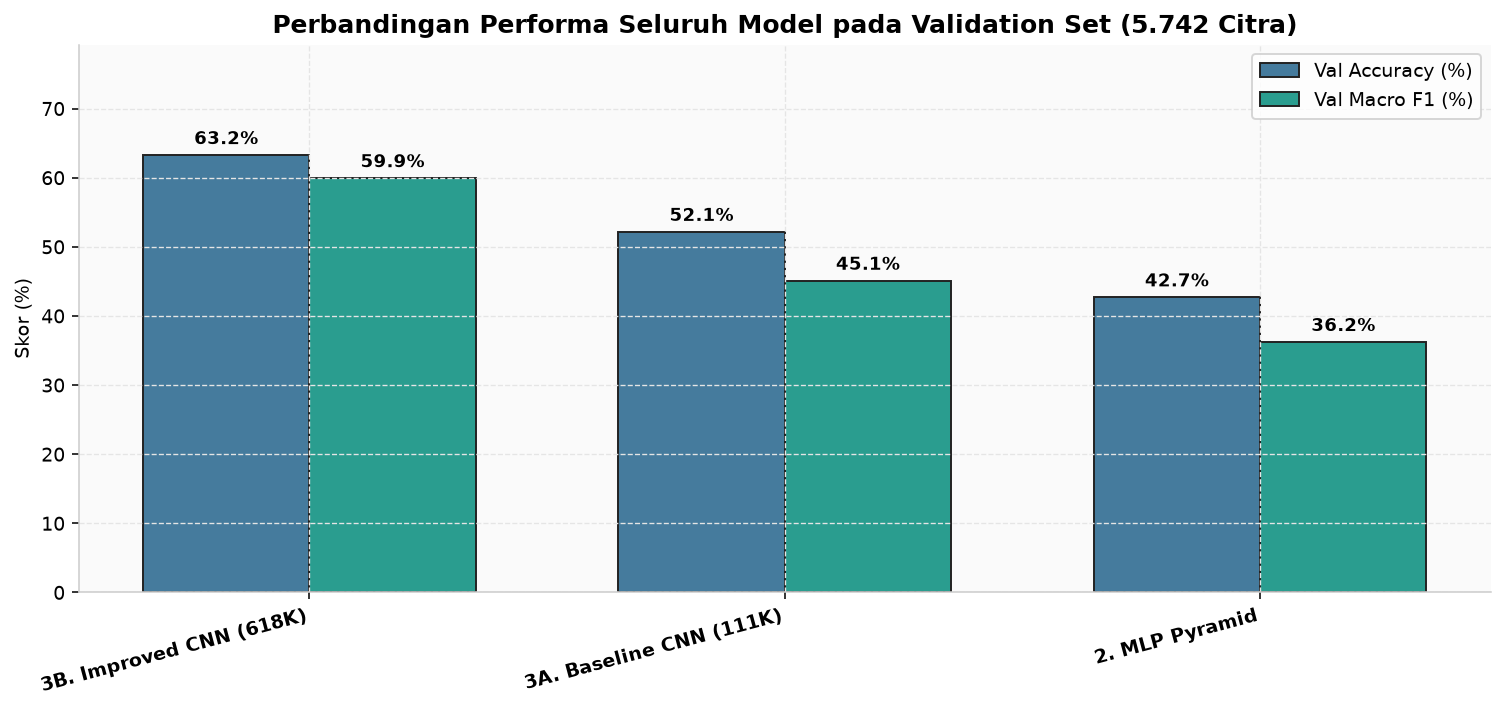

In [12]:
if VAL_BENCHMARKS:
    comp_rows = []
    for label, res in VAL_BENCHMARKS.items():
        per_cls_map = {r["class_name"]: r["f1_score"] * 100 for r in res["per_class"]}
        comp_rows.append({
            "Model": label,
            "Params": res["params"],
            "Size (MB)": res["model_size_mb"],
            "Inf (ms/img)": res["inference_ms_per_img"],
            "Val Acc (%)": round(res["accuracy"] * 100, 2),
            "Val Macro F1 (%)": round(res["macro_f1"] * 100, 2),
            "Val Weighted F1 (%)": round(res["weighted_f1"] * 100, 2),
            "F1 Disgust (%)": round(per_cls_map["Disgust"], 2),
            "F1 Fear (%)": round(per_cls_map["Fear"], 2),
            "F1 Happy (%)": round(per_cls_map["Happy"], 2),
        })
    comp_df = pd.DataFrame(comp_rows).sort_values("Val Macro F1 (%)", ascending=False).reset_index(drop=True)
    display(comp_df)

    # Visualisasi perbandingan Val Accuracy vs Val Macro F1
    fig, ax = plt.subplots(figsize=(11, 5.2))
    x = np.arange(len(comp_df))
    w = 0.35
    b1 = ax.bar(x - w / 2, comp_df["Val Acc (%)"], w, label="Val Accuracy (%)", color="#457B9D", edgecolor="#222222")
    b2 = ax.bar(x + w / 2, comp_df["Val Macro F1 (%)"], w, label="Val Macro F1 (%)", color="#2A9D8F", edgecolor="#222222")
    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(comp_df["Model"], rotation=15, ha="right", fontweight="bold")
    ax.set_ylabel("Skor (%)")
    ax.set_ylim(0, min(100, comp_df["Val Acc (%)"].max() + 16))
    ax.set_title("Perbandingan Performa Seluruh Model pada Validation Set (5.742 Citra)")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(frameon=True, facecolor="white")
    plt.tight_layout()
    plt.show()
else:
    print("Belum ada model di VAL_BENCHMARKS. Jalankan minimal satu model di Tahap 7 terlebih dahulu.")

## Tahap 9 — Evaluasi Akhir pada `Test Set` (`data/raw/test/`, `7.178` Citra)

> **PERINGATAN METODOLOGIS (ANTI-LEAKAGE):**
> Cell di bawah ini **sengaja dikunci (`RUN_FINAL_TEST_EVALUATION = False`)**. Hanya ubah ke `True` **SETELAH seluruh training & pemilihan hyperparameter selesai**! Jangan mengubah arsitektur atau hyperparameter lagi berdasarkan hasil dari cell ini.

### Apa yang dihasilkan cell ini?
1. Memuat seluruh `7.178` citra `data/raw/test/` dengan normalisasi tunggal `[0, 1]` dan **tanpa augmentasi**.
2. Mengevaluasi model pemenang terpilih (`FINAL_MODEL_PATH`, default `models/fer2013_cnn_exp2.keras`).
3. Menampilkan Test Loss, Test Accuracy, Top-2 Accuracy, Macro/Weighted F1, metrik deployment PRD (`model_size_mb` & `inference_time_ms_per_image`), tabel Per-Class Precision/Recall/F1, serta **Confusion Matrix Heatmap (Counts & Normalized %)**.

In [13]:
RUN_FINAL_TEST_EVALUATION = False  # Ubah ke True HANYA saat siap melakukan evaluasi akhir!
FINAL_MODEL_PATH = MODELS_DIR / "fer2013_cnn_exp2.keras"  # Ganti ke model pemenang dari Tahap 8

if RUN_FINAL_TEST_EVALUATION:
    assert FINAL_MODEL_PATH.exists(), f"Model tidak ditemukan: {FINAL_MODEL_PATH}"
    assert RAW_TEST_DIR.exists(), f"Folder data/raw/test tidak ditemukan: {RAW_TEST_DIR}"

    print("Memuat 7.178 citra Test Set dari data/raw/test/ (tanpa augmentasi)...")
    x_test_u8, y_test = load_images_from_manifest(test_df)
    x_test = normalize_pixels(x_test_u8)

    final_model = keras.models.load_model(FINAL_MODEL_PATH)
    test_res = evaluate_keras_model(final_model, x_test, y_test, FINAL_MODEL_PATH, split_label="FINAL TEST")

    display(pd.DataFrame(test_res["per_class"]))
    plot_confusion_matrix_dual(
        test_res["confusion_matrix"],
        title=f"Final Test Confusion Matrix — {final_model.name} (7.178 Citra)",
        save_path=FIGURES_DIR / f"colab_final_{final_model.name.lower()}_cm.png",
    )
else:
    print("Evaluasi Test Set dikunci (RUN_FINAL_TEST_EVALUATION = False) untuk menjaga integritas anti-leakage.")
    print("Set RUN_FINAL_TEST_EVALUATION = True setelah seluruh model selesai dibandingkan di Validation Set.")

Evaluasi Test Set dikunci (RUN_FINAL_TEST_EVALUATION = False) untuk menjaga integritas anti-leakage.
Set RUN_FINAL_TEST_EVALUATION = True setelah seluruh model selesai dibandingkan di Validation Set.


### Q&A
1. **Bagaimana struktur data & split yang dipakai di seluruh eksperimen?** Dataset FER-2013 terdiri atas `35.887` citra grayscale `48×48` (7 kelas, 0 gambar rusak). Folder `data/raw/train/` (`28.709`) dibagi *stratified 80:20* (`seed=42`) menjadi `22.967` Training dan `5.742` Validation, sementara `data/raw/test/` (`7.178`) diisolasi murni untuk evaluasi akhir.
2. **Bagaimana perbandingan hasil model yang sudah dilatih sejauh ini pada Validation Set (`5.742` citra)?**
   - **Model 2 — MLP Pyramid (`1.347.975` param, `15,49 MB`, `0,0438 ms/citra`):** Val Accuracy **`42,67%`**, Val Macro F1 **`36,21%`** (`val_loss = 1,5289`).
   - **Model 3A — Baseline CNN (`110.983` param):** Val Accuracy **`52,14%`**, Val Macro F1 **`45,07%`** (`val_loss = 1,2583`; Test Accuracy `52,22%`, Test Macro F1 `45,09%`).
   - **Model 3B — Improved Custom CNN (`617.895` param):** Val Accuracy **`63,25%`**, Val Macro F1 **`59,91%`** (`val_loss = 1,0761`, Top-2 Acc `81,82%`).
   - **Model 1 (HOG + SVM)** dan **Model 4 (MobileNetV2)** sudah siap dilatih langsung pada Tahap 7 di Google Colab T4 GPU dengan mengatur saklar `RUN_TRAIN_* = True`.

### Data Analysis Key Findings
- **Bias induktif spasial (CNN) sangat menentukan pada citra wajah:** Meski MLP memiliki lebih dari **2× lipat parameter** dibanding Improved CNN (`1,35M` vs `618K`), performanya tertinggal **`-20,58` poin persen** pada Val Accuracy (`42,67%` vs `63,25%`) karena `Flatten()` menghilangkan relasi spasial 2D.
- **Arsitektur Double-Conv + `class_weight="smoothed"` menyelesaikan bottleneck kelas minoritas & sulit:** Dibanding Baseline CNN, Improved CNN menaikkan Val F1 di seluruh 7 kelas, dengan lonjakan terbesar pada `Disgust` (`+28,79 pp`: `23,63% → 52,41%`) dan `Fear` (`+27,77 pp`: `16,45% → 44,23%`).
- **Cache lossless `.npz` (`63,3 MB`) mempercepat eksperimen secara dramatis:** Waktu muat `28.709` citra turun dari `~9 menit` menjadi **`0,41 detik`**, sangat krusial saat berpindah ke Google Drive + Google Colab.

### Insights or Next Steps
- **Eksekusi di Google Colab (T4 GPU):** Upload folder proyek (minimal `data/processed/fer2013_train_val_uint8_cache.npz`, `data/splits/`, `models/`, dan `data/raw/test/`), lalu jalankan Tahap 7 dengan `RUN_TRAIN_HOG_SVM = True` dan `RUN_TRAIN_MOBILENETV2 = True` untuk melengkapi seluruh 4 model PRD dalam hitungan menit.
- **Evaluasi Final & Penulisan Laporan:** Bandingkan keempat model pada Tahap 8 (*Validation Set*), kunci 1–4 evaluasi akhir di Tahap 9 (*Test Set* `7.178` citra), dan gunakan tabel metrik akurasi + efisiensi deployment (`model_size_mb`, `ms/citra`) untuk dokumentasi tugas akhir.